# Exemplos de kernels SVM

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

## Visualização dos dados, margens e vetores de suporte

In [2]:
def plot_svm(model, X, y, title):
    x_limits = (X[:, 0].min() - 0.6, X[:, 0].max() + 0.6)
    y_limits = (X[:, 1].min() - 0.6, X[:, 1].max() + 0.6)
    xx, yy = np.meshgrid(np.linspace(*x_limits, 300), np.linspace(*y_limits, 300))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    decision = model.decision_function(grid).reshape(xx.shape)
    fig, axis = plt.subplots(figsize=(9, 5.5))
    axis.contourf(xx, yy, decision > 0, levels=[-0.5, 0.5, 1.5], colors=["#dbeafe", "#ffedd5"], alpha=0.7)
    axis.contour(xx, yy, decision, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])

    for label, color in [(0, "#2563eb"), (1, "#f97316")]:
        points = X[y == label]
        axis.scatter(points[:, 0], points[:, 1], color=color, s=30, edgecolors="white", linewidths=0.5, label=f"Classe {label}")

    support = model.support_vectors_
    axis.scatter(support[:, 0], support[:, 1], s=110, facecolors="none", edgecolors="black", linewidths=1.2, label="Vetores de suporte")
    handles, _ = axis.get_legend_handles_labels()
    handles += [Line2D([0], [0], color="black", linewidth=2, label="Fronteira: f(x) = 0"), Line2D([0], [0], color="black", linestyle="--", label="Margens: f(x) = ±1")]
    axis.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
    axis.set(xlim=x_limits, ylim=y_limits, xlabel="Atributo 1", ylabel="Atributo 2")
    axis.set_aspect("equal", adjustable="box")
    axis.set_title(title, fontweight="bold", pad=14)
    plt.tight_layout()
    plt.show()

## Exemplo 1 — margens e vetores de suporte

Vetores de suporte: 3
Distância entre as margens: 2.07


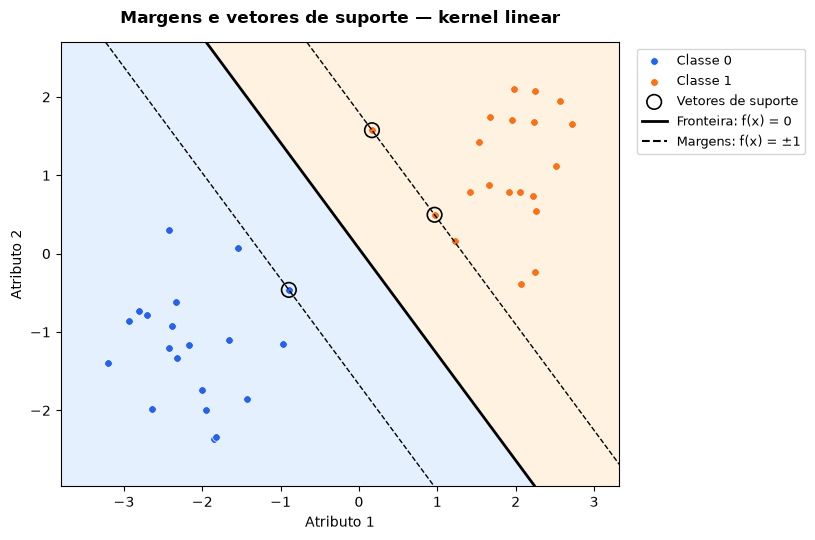

In [3]:
X_blob, y_blob = make_blobs(n_samples=40, centers=[(-2, -1), (2, 1)], cluster_std=0.7, random_state=42)
margin_model = SVC(kernel="linear", C=1)
margin_model.fit(X_blob, y_blob)

print("Vetores de suporte:", len(margin_model.support_))
print(f"Distância entre as margens: {2 / np.linalg.norm(margin_model.coef_[0]):.2f}")
plot_svm(margin_model, X_blob, y_blob, "Margens e vetores de suporte — kernel linear")

## Exemplo 2 — kernel linear em dados não lineares

Acurácia no teste: 89.17%
Vetores de suporte: 104


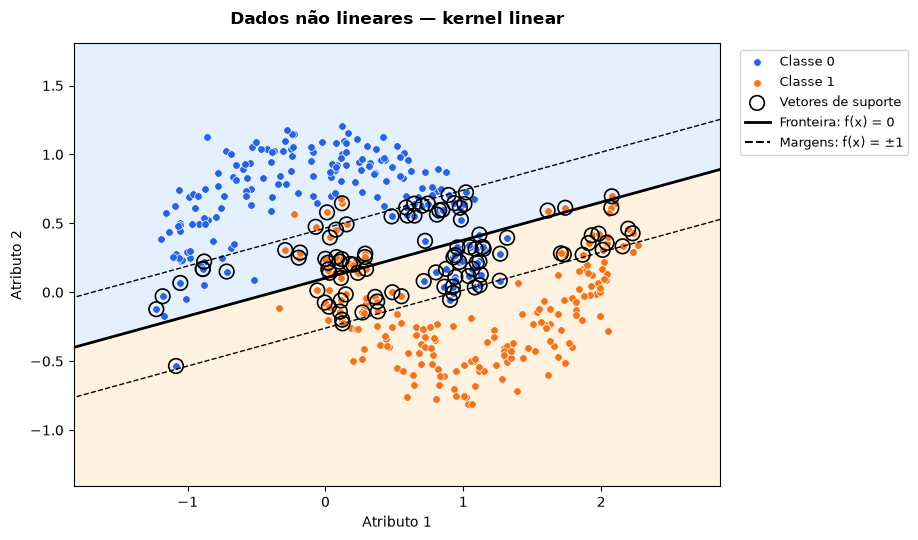

In [4]:
X_nonlinear, y_nonlinear = make_moons(n_samples=400, noise=0.15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_nonlinear, y_nonlinear, test_size=0.3, random_state=42, stratify=y_nonlinear)
linear_model = SVC(kernel="linear", C=1)
linear_model.fit(X_train, y_train)
linear_prediction = linear_model.predict(X_test)

print(f"Acurácia no teste: {accuracy_score(y_test, linear_prediction):.2%}")
print("Vetores de suporte:", len(linear_model.support_))
plot_svm(linear_model, X_nonlinear, y_nonlinear, "Dados não lineares — kernel linear")

## Exemplo 3 — kernel RBF nos mesmos dados não lineares

Acurácia no teste: 96.67%
Vetores de suporte: 53


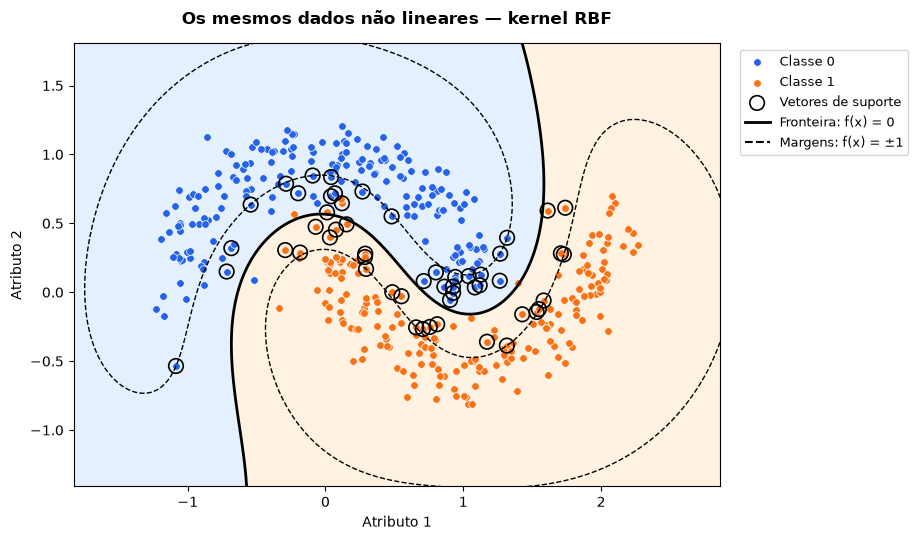

In [5]:
rbf_model = SVC(kernel="rbf", C=1, gamma="scale")
rbf_model.fit(X_train, y_train)
rbf_prediction = rbf_model.predict(X_test)

print(f"Acurácia no teste: {accuracy_score(y_test, rbf_prediction):.2%}")
print("Vetores de suporte:", len(rbf_model.support_))
plot_svm(rbf_model, X_nonlinear, y_nonlinear, "Os mesmos dados não lineares — kernel RBF")